<a href="https://colab.research.google.com/github/Aditttt177/DiditPutraWahyudha_Test_AnalisisSentimen/blob/main/DiditPutraWahyudha_Test_AnalisisSentimen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install google-play-scraper scikit-learn imbalanced-learn Sastrawi wordcloud seaborn matplotlib pandas numpy joblib


  Using cached google_play_scraper-1.2.7-py3-none-any.whl.metadata (50 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 9.3 MB/s eta 0:00:00


In [5]:
from google_play_scraper import Sort, reviews
import pandas as pd
import numpy as np

#Step 1: Scraping ulasan aplikasi Ruangguru
result, continuation_token = reviews(
    'com.ruangguru.livestudents', #Package name aplikasi Ruangguru
    lang='id', #Bahasa Indonesia
    country='id', #Negara Indonesia
    sort=Sort.MOST_RELEVANT, #Ulasan paling relevan
    count=1000, #Jumlah ulasan yang diambil
    filter_score_with=None #Semua rating
)

# Step 2: Mengubah hasil scraping menjadi DataFrame
df_reviews = pd.DataFrame(np.array(result), columns=['review'])
df_reviews = df_reviews.join(pd.DataFrame(df_reviews.pop('review').tolist()))

# Step 3: Memilih kolam yang relevan
new_df = df_reviews[['userName', 'score', 'at', 'content']]

# Step 4: Mengurutkan ulasan berdasarkan tanggal terbaru
sorted_df = new_df.sort_values(by='at', ascending=False)

# Step 5: Menyimpan data ke CSV
my_df = sorted_df[['userName', 'score', 'at', 'content']]
my_df.to_csv("scrapped_data.csv", index=False)

#Step 6: Menampilkan hasil
print("Jumlah ulasan:", len(my_df))
print("Data berhasil disimpan ke file CSV.")
display(my_df.head())

Jumlah ulasan: 1000
Data berhasil disimpan ke file CSV.


,userName,score,at,content
33,Kenosis Miracle yani,5,2026-10-19 02:04:59,aplikasinya sangat interaktif dan membantu say...
92,Nurafni Lala,5,2026-10-17 09:36:49,bagus dan bisa memperlancar anak pintar dan be...
43,Top up robux,5,2026-10-17 09:23:56,the best bagus bener dan juga mudah untuk nger...
35,Rokayah,5,2026-10-16 14:14:38,"belajar jadi lebih mudah,asik,seru dan menyena..."
34,Altaf,5,2026-10-16 05:44:16,ruangguru mantap banget gratis pasti. aku dapa...


In [6]:
import re, json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, roc_auc_score)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Negatif": "#EF4444", "Netral": "#F59E0B", "Positif": "#108981"}
SEED = 42

In [7]:
SCRAPE = False #True = scraping ulang dari Play Store
DATA_PATH = "scrapped_data.csv" #ubah sesuai lokasi file Anda
APP_ID = "com.ruangguru.livestudents"
N_REVIEWS = 1000

if SCRAPE:
    from google_play_scraper import Sort, reviews
    result, _ = reviews(APP_ID, lang="id", country="id", sort=Sort.MOST_RELEVANT, count=N_REVIEWS)
    df_raw = pd.DataFrame(result)[["userName", "score", "at", "content"]]
    df_raw = df_raw.sort_values("at", ascending=False)
    df_raw.to_csv(DATA_PATH, index=False)
else:
    df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")

# Validasi kolom & buang data kosong
assert {"score", "content"}.issubset(df_raw.columns), "Kolom 'score' dan 'content' wajib ada"
df = df_raw.dropna(subset=["content", "score"]).copy()
df["at"] = pd.to_datetime(df["at"], errors="coerce")
df = df.reset_index(drop=True)
print(f"Data dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Data dimuat: 1000 baris, 4 kolom


,userName,score,at,content
0,Kenosis Miracle yani,5,2026-10-19 02:04:59,aplikasinya sangat interaktif dan membantu say...
1,Nurafni Lala,5,2026-10-17 09:36:49,bagus dan bisa memperlancar anak pintar dan be...
2,Top up robux,5,2026-10-17 09:23:56,the best bagus bener dan juga mudah untuk nger...
3,Rokayah,5,2026-10-16 14:14:38,"belajar jadi lebih mudah,asik,seru dan menyena..."
4,Altaf,5,2026-10-16 05:44:16,ruangguru mantap banget gratis pasti. aku dapa...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   userName  1000 non-null   object        
 1   score     1000 non-null   int64         
 2   at        1000 non-null   datetime64[ns]
 3   content   1000 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 31.4+ KB
None

Missing value:
 userName    0
score       0
at          0
content     0
dtype: int64

Rentang tanggal: 15 Sep 2018 - 19 Oct 2026
Ulasan duplikat: 2


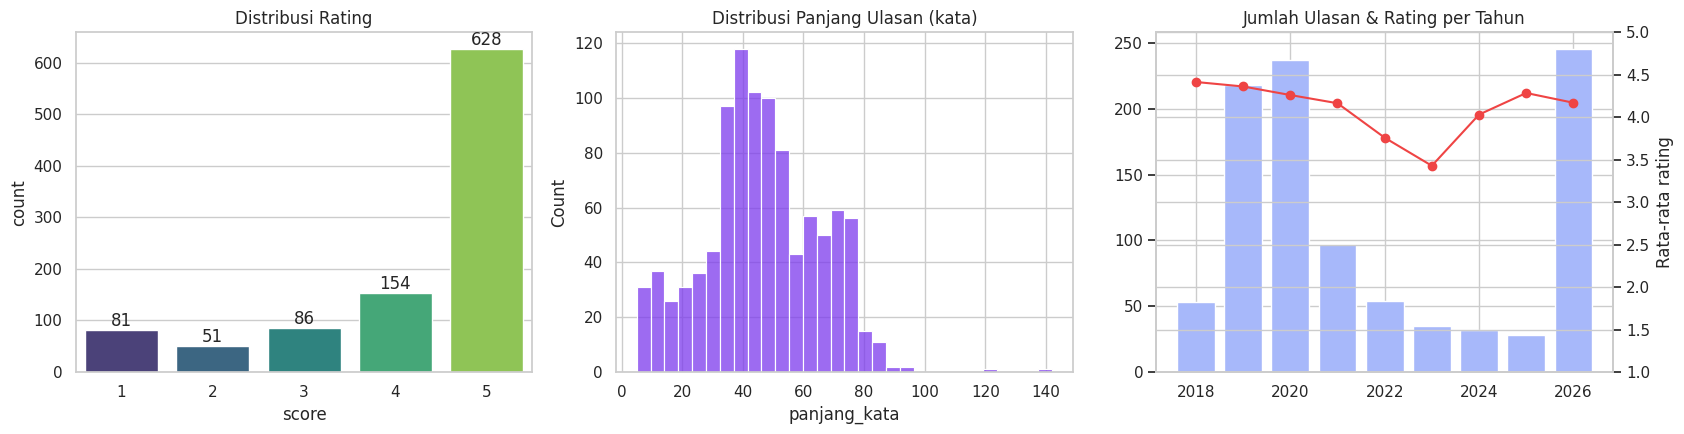

In [8]:
print(df.info())
print("\nMissing value:\n", df.isna().sum())
print(f"\nRentang tanggal: {df['at'].min():%d %b %Y} - {df['at'].max():%d %b %Y}")
print(f"Ulasan duplikat: {df.duplicated(subset='content').sum()}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(data=df, x="score", palette="viridis", ax=ax[0])
ax[0].set_title("Distribusi Rating")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2., p.get_height()), ha="center", va="bottom")

df["panjang_kata"] = df["content"].astype(str).str.split().str.len()
sns.histplot(df["panjang_kata"], bins=30, color="#7C3AED", ax=ax[1])
ax[1].set_title("Distribusi Panjang Ulasan (kata)")

yr = df.dropna(subset=["at"]).groupby(df["at"].dt.year).agg(jumlah=("score", "size"), rating=("score", "mean"))
ax[2].bar(yr.index, yr["jumlah"], color="#A7B8FA")
ax2 = ax[2].twinx(); ax2.plot(yr.index, yr["rating"], color="#EF4444", marker="o"); ax2.set_ylim(1, 5); ax2.set_ylabel("Rata-rata rating")
ax[2].set_title("Jumlah Ulasan & Rating per Tahun")
plt.tight_layout(); plt.show()

label
Positif    782
Negatif    132
Netral      86
Name: count, dtype: int64
label
Positif    78.2%
Negatif    13.2%
Netral      8.6%
Name: count, dtype: object


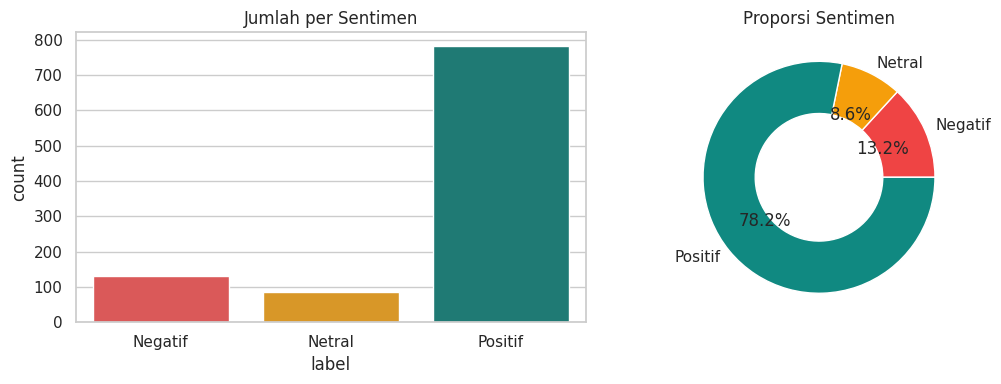

In [9]:
def beri_label(score):
    if score <= 2: return "Negatif"
    if score == 3: return "Netral"
    return "Positif"

df["label"] = df["score"].apply(beri_label)
dist = df["label"].value_counts()
print(dist)
print((dist / dist.sum() * 100).round(1).astype(str) + "%")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = ["Negatif", "Netral", "Positif"]
sns.countplot(data=df, x="label", order=order, palette=PALETTE, ax=ax[0]); ax[0].set_title("Jumlah per Sentimen")
ax[1].pie(dist[order], labels=order, autopct="%.1f%%", colors=[PALETTE[o] for o in order], wedgeprops=dict(width=.45))
ax[1].set_title("Proporsi Sentimen"); plt.tight_layout(); plt.show()

In [10]:
STOPWORDS = [
    "di", "dari", "ke", "pada", "dengan", "untuk", "oleh", "tentang", "kepada", "yang", "dan", "atau", "tetapi", "tapi",
    "karena", "meskipun", "jika", "agar", "saya", "aku", "kamu", "dia", "kita", "mereka", "ini", "itu", "lah", "tuh", "nya",
    "dong", "aja", "gitu", "deh", "emang", "ya", "sih", "kok", "lho", "nih", "si", "pun", "juga", "sudah", "akan", "lagi",
    "pernah", "hanya", "adalah", "dalam", "ada", "para", "sebagai", "saat", "ketika", "kalau", "kalo", "jadi", "sama", "mau",
]
NEGATIONS = {"tidak", "bukan", "belum", "jangan", "kurang", "gak", "ga", "nggak", "ngga", "tak", "gk", "enggak"}
DOMAIN_STOPWORDS = {"ruangguru", "rg", "ruang", "kak"} #muncul di hampir semua ulasan

SLANG = {
    "gak":"tidak", "ga":"tidak", "nggak":"tidak", "ngga":"tidak", "gk":"tidak", "enggak":"tidak","tdk":"tidak", "tak":"tidak",
    "bgt":"banget", "bgus":"bagus", "bagu": "bagus", "bagust":"bagus", "mantul":"mantap", "udh":"sudah", "udah":"sudah",
    "sdh":"sudah","blm":"belum", "yg":"yang", "dgn": "dengan", "krn":"karena", "karna":"karena", "utk":"untuk", "jd":"jadi",
    "tp":"tapi", "tpi":"tapi", "klo": "kalau", "kalo":"kalau", "sy":"saya", "sm":"sama", "sma":"sama", "bs":"bisa", "bsa":"bisa",
    "gabisa":"tidak bisa", "lemot":"lambat", "lag":"lambat", "ngelag":"lambat", "eror":"error", "erorr":"error",
    "apk":"aplikasi", "app": "aplikasi", "aplikasinya":"aplikasi", "thx":"terima kasih", "makasih":"terima kasih",
    "terimakasih":"terima kasih", "trims": "terima kasih", "oke":"ok", "okey": "ok", "recomended":"recommended",
    "rekomen":"recommended", "kereen":"keren", "jelek":"buruk", "jlek":"buruk", "pake":"pakai", "pke":"pakai",
    "jg":"juga","dr":"dari", "dl":"dulu", "bgmn": "bagaimana", "gmn": "bagaimana", "knp": "kenapa", "kyk":"seperti",
    "bnyk":"banyak", "bebrpa": "beberapa",
}

# Stemmer Sastrawi (lambat, jadi hasil per-kata disimpan di cache)
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
stemmer = StemmerFactory().create_stemmer()
STEM_CACHE_FILE = "stem_cache.json"
stem_cache = json.load(open(STEM_CACHE_FILE, encoding="utf-8")) if os.path.exists(STEM_CACHE_FILE) else {}

def stem_kata(w):
    if w not in stem_cache:
        stem_cache[w] = stemmer.stem(w)
    return stem_cache[w]

def bersihkan_teks(teks, stemming=True, hapus_stopword=True):
    t = str(teks).lower()
    t = re.sub(r"http\S+|www\.\S+","", t) # URL
    t = re.sub(r"\bruang\s+guru\b", "ruangguru", t) # satukan nama aplikasi
    t = re.sub(r"(.)\1{2,}", r"\1", t) # baguuus -> bagus
    t = re.sub(r"[^a-z\s]", "", t) # angka, simbol, emoji

    tokens = " ".join(SLANG.get(w, w) for w in t.split()).split()
    if hapus_stopword:
        tokens = [w for w in tokens if (w not in STOPWORDS or w in NEGATIONS) and w not in DOMAIN_STOPWORDS]
    tokens = [w for w in tokens if len(w) > 1]

    if stemming:
        tokens = [stem_kata(w) for w in tokens]
    return " ".join(tokens)

contoh = "Aplikasinya bgt membantuuu!! tpi kadang lemot & gak bisa login https://x.id"
print("Asli:", contoh)
print("Bersih:", bersihkan_teks(contoh))

Asli: Aplikasinya bgt membantuuu!! tpi kadang lemot & gak bisa login https://x.id
Bersih: aplikasi banget bantu kadang lambat tidak bisa login


In [11]:
%%time
# Proses semua ulasan (pertama kali 2-3 menit karena stemming, berikutnya cepat berkat cache)
df["clean_content"] = df["content"].apply(bersihkan_teks)

json.dump(stem_cache, open(STEM_CACHE_FILE, "w", encoding="utf-8"), ensure_ascii=False)

# Buang ulasan yang kosong setelah dibersihkan
n0 = len(df)
df = df[df["clean_content"].str.strip().str.len() > 0].reset_index(drop=True)
df["jumlah_kata"] = df["clean_content"].str.split().str.len()
print(f"Data setelah preprocessing: {len(df)} (dibuang {n0 - len(df)})")
df[["content", "clean_content", "label"]].sample(5, random_state=3)

Data setelah preprocessing: 999 (dibuang 1)
CPU times: user 7min 56s, sys: 593 ms, total: 7min 57s
Wall time: 9min 22s


,content,clean_content,label
642,Belajarku jadi efisien dan efektif untuk utbk ...,ajar efisien efektif utbk terima kasih akhir s...,Positif
761,"Bagus banget, gara"" ruang guru nilai fisika ak...",bagus banget gara nilai fisika naik awal bisa ...,Positif
908,"kerenn sih aplikasi ini:)) tutornya asik, vide...",kerenn aplikasi tutor asik video mudah erti an...,Positif
199,"keren, belajar jadi gampang karena adanya visu...",keren ajar gampang ada visualisasi mudah paham...,Positif
586,Saya sarankan untuk rekamannya agar lebih dipe...,saran rekam lebih perhati kemarin beli paket k...,Negatif


In [12]:
%%writefile app.py
from __future__ import annotations
import io
import json
import os
import re
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from wordcloud import WordCloud

# Folder = tempat file ini berada. Untuk folder lain, isi manual, mis.:
# BASE_DIR="/Users/murniramadhani/Documents/Kuliah Analisis Big Data /Data Sentimen"
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_FILE, DATA_FILE, STEM_FILE = "model_nb_sentimen.joblib", "data_bersih_berlabel.csv", "stem_cache.json"
SEED, TEST_SIZE = 42, 0.2
# HARUS sama dengan notebook agar data uji identik
COLORS = {"Positif": "#10B981", "Netral": "#F59E0B", "Negatif": "#EF4444"}

st.set_page_config(page_title="Sentiment Mining - Ruangguru", page_icon="📊", layout="wide")
st.markdown("""
<style>
.hero{background: linear-gradient(120deg, #4F46E5 0%, #7C3AED 55%, #EC4899 100%); padding:26px 32px;
border-radius: 18px;color:white;margin-bottom:16px}
.hero h1{margin:0;font-size:1.9rem;color:white} .hero p{margin:6px 0 0; opacity:.92}
.kpi{background: var(--secondary-background-color); border-radius: 14px; padding:14px 18px; border-left:6px solid #7C3AED}
.kpi .v{font-size:1.65rem; font-weight:700} .kpi .l{font-size:.78rem; opacity:.7;text-transform:uppercase; letter-spacing:.05em}
.insight{background: var(--secondary-background-color); border-radius: 12px; padding:10px 16px; margin:6px 0; border-left: 4px solid #EC4899}
.stTabs [data-baseweb="tab"] {font-weight:600}
</style>
<div class="hero"><h1>📊 Sentiment Mining Dashboard - Ruangguru</h1>
<p>Hasil analisis notebook dengan <b>Multinomial Naive Bayes</b> TF-IDF SMOTE • Influential Features • Analisis Aspek</p></div>
""", unsafe_allow_html=True)

def kpi(col, label, value, color="#7C3AED"):
    col.markdown(f'<div class="kpi" style="border-left-color:{color}"><div class="l">{label}</div>'
                 f'<div class="v">{value}</div></div>', unsafe_allow_html=True)

def _find(name):
    p = os.path.join(BASE_DIR, name)
    return p if os.path.exists(p) else None

with st.sidebar:
    st.header("📂 Hasil Notebook")
    up_model = st.file_uploader("Model (.joblib) opsional", type="joblib", help="Isi hanya jika file tidak ada di folder aplikasi.")
    up_data = st.file_uploader("Data bersih (.csv) opsional", type="csv")
    model_src = up_model.getvalue() if up_model else _find(MODEL_FILE)
    data_src = up_data.getvalue() if up_data else _find(DATA_FILE)

if model_src is None or data_src is None:
    st.error("File hasil notebook belum ditemukan.")
    st.markdown(f"""
    Letakkan file berikut **satu folder dengan `app_streamlit.py`** (folder saat ini: `{BASE_DIR}`):
    - `{MODEL_FILE}`
    - `{DATA_FILE}`

    File ini dibuat otomatis oleh **sel terakhir (bagian 11 Simpan Model)** di notebook. Jalankan notebook sampai sel itu,
    atau unggah kedua file lewat sidebar.
    """)
    st.stop()

@st.cache_resource(show_spinner="Memuat model...")
def load_bundle(src):
    return joblib.load(io.BytesIO(src) if isinstance(src, bytes) else src)

@st.cache_data(show_spinner="Memuat data...")
def load_data(src):
    d = pd.read_csv(io.BytesIO(src) if isinstance(src, bytes) else src)
    d["clean_content"] = d["clean_content"].fillna("").astype(str)
    d["at"] = pd.to_datetime(d.get("at"), errors="coerce") if "at" in d.columns else pd.NaT
    return d

bundle = load_bundle(model_src)
df = load_data(data_src)
vec, model = bundle["vectorizer"], bundle["model"]
classes = list(model.classes_)
bp = bundle.get("best_params", {})
cmap = {c: COLORS.get(c, "#6366F1") for c in classes}
fitur = np.array(vec.get_feature_names_out())
flp = model.feature_log_prob_

@st.cache_resource(show_spinner="Menghitung evaluasi pada data uji...")
def build_eval(_key, _df, _vec, _model):
    """Membentuk ulang data uji yang SAMA dengan notebook (split deterministik) lalu hanya memprediksi."""
    X_tr, X_te, y_tr, y_te = train_test_split(_df["clean_content"], _df["label"],
                                              test_size=TEST_SIZE, stratify=_df["label"], random_state=SEED)
    cls = list(_model.classes_)
    y_pred = _model.predict(_vec.transform(X_te))
    prob = _model.predict_proba(_vec.transform(X_te))

    #ROC One-vs-Rest
    roc = {}
    if len(cls) == 2:
        yb = (y_te == cls[1]).astype(int)
        f, t, _ = roc_curve(yb, prob[:, 1]); roc[cls[1]] = (f, t, roc_auc_score(yb, prob[:, 1]))
    else:
        Y = label_binarize(y_te, classes=cls)
        for i, c in enumerate(cls):
            f, t, _ = roc_curve(Y[:, i], prob[:, i]); roc[c] = (f, t, roc_auc_score(Y[:, i], prob[:, i]))

    metrics = {
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision (macro)": precision_score(y_te, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_te, y_pred, average="macro", zero_division=0),
        "F1-Score (macro)": f1_score(y_te, y_pred, average="macro", zero_division=0),
        "F1-Score (weighted)": f1_score(y_te, y_pred, average="weighted", zero_division=0),
        "ROC-AUC (macro)": float(np.mean([v[2] for v in roc.values()])),
    }

    rep = pd.DataFrame(classification_report(y_te, y_pred, output_dict=True, zero_division=0)).T
    errors = pd.DataFrame({"ulasan": X_te.values, "aktual": y_te.values, "prediksi": y_pred, "keyakinan": prob.max(axis=1)})
    errors = errors[errors["aktual"] != errors["prediksi"]].sort_values("keyakinan", ascending=False)

    return dict(classes=cls, metrics=metrics, report=rep, cm=confusion_matrix(y_te, y_pred, labels=cls), roc=roc,
                errors=errors, X_tr=X_tr, y_tr=y_tr, n_tr=len(X_tr), n_te=len(X_te), y_te=y_te, y_pred=y_pred)

ev = build_eval(f"{len(df)}-{len(fitur)}-{bundle.get('metrics', {}).get('Accuracy', 0):.6f}", df, vec, model)
M = ev["metrics"]

saved_acc = bundle.get("metrics", {}).get("Accuracy")
in_sync = saved_acc is None or abs(saved_acc - M["Accuracy"]) < 1e-9

with st.sidebar:
    st.divider()
    st.subheader("⚙ Model")
    st.markdown(f"""
    Algoritma: **Multinomial Naive Bayes**
    - `alpha`: {bp.get('nb__alpha', model.alpha)}
    - `n-gram`: {bp.get('tfidf__ngram_range', vec.ngram_range)}
    - `max_features`: {bp.get('tfidf__max_features', vec.max_features)}
    - `min_df`: {bp.get('tfidf__min_df', vec.min_df)}

    Fitur TF-IDF: {len(fitur):,}
    Data latih / uji: {ev['n_tr']} / {ev['n_te']}
    """)
    if in_sync:
        st.success("Hasil identik dengan notebook ✅")
    else:
        st.warning("Akurasi berbeda dari yang tersimpan di notebook. Pastikan model & data berasal dari proses yang sama.")

# ==============================================================================
# 2. FUNGSI BANTU (preprocessing HANYA untuk teks baru pada tab Prediksi)
# ==============================================================================
STOPWORDS = {
    "di", "dari", "ke", "pada", "dengan", "untuk", "oleh", "tentang", "kepada", "yang", "dan", "atau", "tetapi", "tapi",
    "karena", "meskipun", "jika", "agar", "saya", "aku", "kamu", "dia", "kita", "mereka", "ini", "itu", "lah", "tuh", "nya",
    "dong", "aja", "gitu", "deh", "emang", "ya", "sih", "kok", "lho", "nih", "si", "pun", "juga", "sudah", "akan", "lagi",
    "pernah", "hanya", "adalah", "dalam", "ada", "para", "sebagai", "saat", "ketika", "kalau", "kalo", "jadi", "sama", "mau",
}
NEGATIONS = {"tidak", "bukan", "belum", "jangan", "kurang", "gak", "ga", "nggak", "ngga", "tak", "gk", "enggak"}
DOMAIN_STOPWORDS = {"ruangguru", "rg", "ruang", "kak"}

SLANG = {
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "ngga": "tidak", "gk": "tidak", "enggak": "tidak", "tdk": "tidak",
    "tak": "tidak", "bgt": "banget", "bgus": "bagus", "bagu": "bagus", "bagust": "bagus", "mantul": "mantap", "udh": "sudah",
    "udah": "sudah", "sdh": "sudah", "blm": "belum", "yg": "yang", "dgn": "dengan", "krn": "karena", "karna": "karena",
    "utk": "untuk", "jd": "jadi", "tp": "tapi", "tpi": "tapi", "klo": "kalau", "kalo": "kalau", "sy": "saya", "sm": "sama",
    "sma": "sama", "bs": "bisa", "bsa": "bisa", "gabisa": "tidak bisa", "lemot": "lambat", "lag": "lambat",
    "ngelag": "lambat", "eror": "error", "erorr": "error", "apk": "aplikasi", "app": "aplikasi", "aplikasinya": "aplikasi",
    "thx": "terima kasih", "makasih": "terima kasih", "terimakasih": "terima kasih", "trims": "terima kasih", "oke": "ok",
    "okey": "ok", "recomended": "recommended", "rekomen": "recommended", "kereen": "keren", "jelek": "buruk",
    "jlek": "buruk", "pake": "pakai", "pke": "pakai", "jg": "juga", "dr": "dari", "dl": "dulu", "bgmn": "bagaimana",
    "gmn": "bagaimana", "knp": "kenapa", "kyk": "seperti", "bnyk": "banyak", "bebrpa": "beberapa",
}

_STEM_PATH = os.path.join(BASE_DIR, STEM_FILE)
_stem_cache: dict = {}
if os.path.exists(_STEM_PATH):
    try:
        _stem_cache = json.load(open(_STEM_PATH, encoding="utf-8"))
    except (OSError, ValueError):
        _stem_cache = {}

@st.cache_resource(show_spinner="Memuat stemmer Sastrawi...")
def get_stemmer():
    try:
        from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    except ImportError:
        return None
    return StemmerFactory().create_stemmer()

def stem_kata(w):
    if w not in _stem_cache:
        s = get_stemmer()
        _stem_cache[w] = s.stem(w) if s else w
    return _stem_cache[w]

def bersihkan_teks(teks):
    t = str(teks).lower()
    t = re.sub(r"http\S+|www\.\S+", "", t)
    t = re.sub(r"\bruang\s+guru\b", "ruangguru", t)
    t = re.sub(r"(.)\1{2,}", r"\1", t)
    t = re.sub(r"[^a-z\s]", "", t)

    tokens = " ".join(SLANG.get(w, w) for w in t.split()).split()
    tokens = [w for w in tokens if (w not in STOPWORDS or w in NEGATIONS) and w not in DOMAIN_STOPWORDS and len(w) > 1]
    return " ".join(stem_kata(w) for w in tokens)

def simpan_stem_cache():
    try:
        json.dump(_stem_cache, open(_STEM_PATH, "w", encoding="utf-8"), ensure_ascii=False)
    except OSError:
        pass

ASPEK = {
    "Mentor / Guru": r"guru|mentor|pengajar|tutor|kakak|penjelasan|menjelaskan",
    "Materi & Soal": r"materi|soal|latihan|rangkuman|pembahasan|kuis|pelajaran|kurikulum|bab",
    "Video & Animasi": r"video|animasi|tayang|nonton|subtitle|suara",
    "Harga & Langganan": r"harga|mahal|langganan|berlangganan|paket|bayar|biaya|promo|diskon|gratis|saldo|refund",
    "Teknis & Performa": r"error|bug|crash|lemot|lambat|loading|download|kuota|login|update|hang|ngelag|tidak bisa|gak bisa|susah",
    "Fitur & Tampilan": r"fitur|tampilan|menu|interface|desain|navigasi|opsi",
    "Layanan & Iklan": r"spam|iklan|telepon|sales|cs|customer|layanan|notifikasi|tawar",
}

@st.cache_data(show_spinner=False)
def aspect_table(_df, key):
    low = _df["content"].astype(str).str.lower()
    rows = []
    for nama, pola in ASPEK.items():
        m = low.str.contains(pola, regex=True); sub = _df[m]
        rows.append({"Aspek": nama, "Jumlah Ulasan": int(m.sum()), "Porsi (%)": m.mean() * 100,
                     "Rata-rata Rating": sub["score"].mean(),
                     "% Negatif": (sub["label"] == "Negatif").mean() * 100,
                     "% Netral": (sub["label"] == "Netral").mean() * 100,
                     "% Positif": (sub["label"] == "Positif").mean() * 100})
    return pd.DataFrame(rows).sort_values("Jumlah Ulasan", ascending=False).reset_index(drop=True)

def influential(top_n=15):
    rows = []
    for i, c in enumerate(classes):
        diff = flp[i] - np.delete(flp, i, axis=0).mean(axis=0)
        for rank, j in enumerate(np.argsort(diff)[::-1][:top_n], 1):
            rows.append({"Kelas": c, "Rank": rank, "Fitur": fitur[j], "Skor Pengaruh": diff[j],
                         "Rasio Odds": float(np.exp(diff[j])), "log P(kata|kelas)": flp[i, j]})
    return pd.DataFrame(rows)

def prediksi(teks, top_k=8):
    bersih = bersihkan_teks(teks)
    if not bersih.strip():
        return None
    X = vec.transform([bersih])
    p = model.predict_proba(X)[0]

    order = np.argsort(p)[::-1]
    pred, ref = classes[order[0]], classes[order[1]]

    kontrib = [{"Kata": fitur[j], "TF-IDF": float(X[0, j]),
                f"Dorongan ke {pred}": float((flp[classes.index(pred), j] - flp[classes.index(ref), j]) * X[0, j])}
               for j in X.nonzero()[1]]

    cdf = pd.DataFrame(kontrib)
    if not cdf.empty:
        cdf = cdf.sort_values(cdf.columns[-1], ascending=False).head(top_k).reset_index(drop=True)

    return {"clean": bersih, "pred": pred, "proba": dict(zip(classes, p)), "contrib": cdf}

# ==============================================================================
# 3. TAMPILAN
# ==============================================================================
tabs = st.tabs(["📊 Ringkasan", "📈 Eksplorasi Data", "💬 Analisis Teks", "🎯 Evaluasi Model",
                "🔑 Influential Features", "🧩 Aspek & Anomali", "🤖 Prediksi", "📝 Metodologi"])

# ----------------- RINGKASAN -----------------
with tabs[0]:
    c = st.columns(5)
    for col, (k, v), colr in zip(c, [(k, M[k]) for k in ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-Score (macro)", "ROC-AUC (macro)"]], ["#4F46E5", "#10B981", "#F59E0B", "#EC4899", "#06B6D4"]):
        kpi(col, k, f"{v*100:.1f}%" if "AUC" not in k else f"{v:.3f}", colr)

    st.write("")
    c = st.columns(4)
    kpi(c[0], "Total Ulasan", f"{len(df):,}")
    kpi(c[1], "Rata-rata Rating", f"{df['score'].mean():.2f}", "#F59E0B")
    kpi(c[2], "% Positif", f"{(df['label']=='Positif').mean()*100:.1f}%", "#10B981")
    kpi(c[3], "% Negatif", f"{(df['label']=='Negatif').mean()*100:.1f}%", "#EF4444")

    st.subheader("💡 Temuan Utama")
    rep = ev["report"].loc[classes]
    best_c, worst_c = rep["f1-score"].idxmax(), rep["f1-score"].idxmin()
    asp = aspect_table(df, len(df))
    neg_asp = asp.sort_values("% Negatif", ascending=False).iloc[0]
    top_asp = asp.iloc[0]

    insights = [
        f"Model paling baik mengenali kelas **{best_c}** (F1 = {rep.loc[best_c, 'f1-score']:.2f}) dan paling lemah pada kelas **{worst_c}** (F1 = {rep.loc[worst_c, 'f1-score']:.2f}).",
        f"Aspek yang paling sering dibahas adalah **{top_asp['Aspek']}** ({top_asp['Porsi (%)']:.0f}% ulasan), sedangkan aspek paling negatif adalah **{neg_asp['Aspek']}** ({neg_asp['% Negatif']:.0f}% ulasan negatif)."
    ]

    if df["at"].notna().any():
        yr = df.dropna(subset=["at"]).groupby(df["at"].dt.year)["score"].agg(["mean", "size"])
        yr = yr[yr["size"] >= 20]
        if len(yr):
            insights.append(f"Rata-rata rating tertinggi tercatat pada tahun **{int(yr['mean'].idxmax())}** ({yr['mean'].max():.2f}) dan terendah pada **{int(yr['mean'].idxmin())}** ({yr['mean'].min():.2f}).")

    imb = df["label"].value_counts(normalize=True)
    insights.append(f"Data **tidak seimbang**: kelas {imb.idxmax()} mendominasi ({imb.max()*100:.0f}%), sehingga **F1-macro ({M['F1-Score (macro)']:.2f})** lebih jujur daripada akurasi ({M['Accuracy']:.2f}).")

    for t in insights:
        st.markdown(f'<div class="insight">{t}</div>', unsafe_allow_html=True)

    a, b = st.columns(2)
    lb = df["label"].value_counts().reset_index(); lb.columns = ["Sentimen", "Jumlah"]
    a.plotly_chart(px.pie(lb, names="Sentimen", values="Jumlah", hole=.55, color="Sentimen", color_discrete_map=cmap, title="Distribusi Sentimen"), width="stretch")

    rp = rep[["precision", "recall", "f1-score"]].reset_index().melt("index", var_name="Metrik", value_name="Nilai")
    b.plotly_chart(px.bar(rp, x="index", y="Nilai", color="Metrik", barmode="group", range_y=[0, 1], title="Kinerja per Kelas (data uji)", labels={"index": "Kelas"}), width="stretch")

# ----------------- EKSPLORASI -----------------
with tabs[1]:
    d = df.copy()
    f1c, f2c = st.columns(2)

    if d["at"].notna().any():
        yrs = sorted(d["at"].dropna().dt.year.unique())
        yr_sel = f1c.select_slider("Rentang tahun", options=yrs, value=(yrs[0], yrs[-1]))
        d = d[d["at"].dt.year.between(*yr_sel) | d["at"].isna()]

    lab_sel = f2c.multiselect("Sentimen", classes, default=classes)
    d = d[d["label"].isin(lab_sel)]
    st.caption(f"{len(d):,} ulasan terpilih")

    a, b = st.columns(2)
    sc = d["score"].value_counts().sort_index().reset_index(); sc.columns = ["Rating", "Jumlah"]
    a.plotly_chart(px.bar(sc, x="Rating", y="Jumlah", text="Jumlah", color="Rating", color_continuous_scale="Viridis", title="Distribusi Rating"), width="stretch")

    d["panjang_kata"] = d["content"].astype(str).str.split().str.len()
    b.plotly_chart(px.histogram(d, x="panjang_kata", color="label", nbins=30, barmode="overlay", opacity=.7, color_discrete_map=cmap, title="Panjang Ulasan (kata)"), width="stretch")

    if d["at"].notna().any():
        dd = d.dropna(subset=["at"]).copy()
        dd["Tahun"] = dd["at"].dt.year
        a, b = st.columns(2)
        t = dd.groupby(["Tahun", "label"]).size().reset_index(name="Jumlah")
        a.plotly_chart(px.bar(t, x="Tahun", y="Jumlah", color="label", color_discrete_map=cmap, title="Jumlah Ulasan per Tahun"), width="stretch")

        r = dd.groupby("Tahun")["score"].agg(["mean", "size"]).reset_index(); r.columns = ["Tahun", "Rating", "Jumlah"]
        fig = px.line(r, x="Tahun", y="Rating", markers=True, hover_data=["Jumlah"], title="Rata-rata Rating per Tahun")
        fig.update_traces(line_color="#7C3AED"); fig.update_yaxes(range=[1, 5])
        b.plotly_chart(fig, width="stretch")

    st.subheader("📋 Tabel Ulasan")
    q = st.text_input("Cari kata di ulasan")
    tb = d[d["content"].astype(str).str.contains(q, case=False, regex=False)] if q else d
    st.dataframe(tb[[c for c in ["at", "score", "label", "content"] if c in tb.columns]].head(300), width="stretch")

# ----------------- TEKS -----------------
with tabs[2]:
    pick = st.selectbox("WordCloud untuk", ["Semua"] + classes)
    txt = " ".join(df["clean_content"] if pick == "Semua" else df.loc[df["label"] == pick, "clean_content"])

    if txt.strip():
        cm_name = {"Negatif": "Reds", "Netral": "Oranges", "Positif": "Greens"}.get(pick, "viridis")
        wc = WordCloud(width=1000, height=420, background_color="white", colormap=cm_name, max_words=100, random_state=SEED).generate(txt)
        fig, ax = plt.subplots(figsize=(11, 4.6)); ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
        st.pyplot(fig)

    cols = st.columns(len(classes))
    for col, c in zip(cols, classes):
        top = pd.Series(" ".join(df.loc[df["label"] == c, "clean_content"]).split()).value_counts().head(12)[::-1]
        col.plotly_chart(px.bar(x=top.values, y=top.index, orientation="h", title=f"Kata teratas {c}", color_discrete_sequence=[cmap[c]], labels={"x": "Frekuensi", "y": ""}), width="stretch")

    st.divider()
    st.subheader("🔍 Penelusur Kata")
    kw = st.text_input("Ketik kata/frasa (mis. error, mahal, guru, video)")
    if kw:
        m = df["content"].astype(str).str.contains(kw, case=False, regex=False)
        st.write(f"**{int(m.sum())}** ulasan menyebut '{kw}', rata-rata rating **{df.loc[m, 'score'].mean():.2f}**")
        if m.sum():
            dist = df.loc[m, "label"].value_counts().reset_index(); dist.columns = ["Sentimen", "Jumlah"]
            a, b = st.columns([1, 2])
            a.plotly_chart(px.pie(dist, names="Sentimen", values="Jumlah", hole=.5, color="Sentimen", color_discrete_map=cmap), width="stretch")
            b.dataframe(df.loc[m, ["score", "label", "content"]].head(50), width="stretch")

# ----------------- EVALUASI -----------------
with tabs[3]:
    c = st.columns(6)
    for col, (k, v), colr in zip(c, M.items(), ["#4F46E5", "#10B981", "#F59E0B", "#EC4899", "#8B5CF6", "#06B6D4"]):
        kpi(col, k, f"{v*100:.2f}%" if "AUC" not in k else f"{v:.3f}", colr)

    st.write("")
    a, b = st.columns(2)

    cm = ev["cm"]; cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    mode = a.radio("Tampilan confusion matrix", ["Jumlah", "% per kelas aktual (recall)"], horizontal=True)
    z, fmt = (cm, "d") if mode == "Jumlah" else (cm_pct, ".1f")
    a.plotly_chart(px.imshow(z, x=classes, y=classes, text_auto=fmt, color_continuous_scale="Purples", labels=dict(x="Prediksi", y="Aktual", color=""), title="Confusion Matrix"), width="stretch")

    fig = go.Figure()
    for cl, (fpr, tpr, auc) in ev["roc"].items():
        fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines", name=f"{cl} (AUC={auc:.3f})", line=dict(width=3, color=cmap.get(cl))))
    fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(dash="dash", color="gray"), showlegend=False))
    fig.update_layout(title="ROC Curve (One-vs-Rest)", xaxis_title="False Positive Rate", yaxis_title="True Positive Rate")
    b.plotly_chart(fig, width="stretch")

    st.subheader("Classification Report")
    st.dataframe(ev["report"].style.format("{:.3f}").background_gradient(cmap="Purples", subset=["precision", "recall", "f1-score"]), width="stretch")

    st.subheader("Cross-Validation (opsional)")
    st.caption("Menghitung ulang TF-IDF + SMOTE + Naive Bayes di tiap fold pada data latih dengan parameter terbaik dari notebook.")
    nf = st.slider("Jumlah fold", 3, 10, 5)

    if st.button("Jalankan Cross-Validation"):
        from imblearn.over_sampling import SMOTE, RandomOverSampler
        from imblearn.pipeline import Pipeline as ImbPipeline
        from sklearn.feature_extraction.text import TfidfVectorizer
        from sklearn.model_selection import StratifiedKFold, cross_validate
        from sklearn.naive_bayes import MultinomialNB

        mn = int(ev["y_tr"].value_counts().min() * (nf - 1) / nf)
        smp = SMOTE(k_neighbors=min(5, mn - 1), random_state=SEED) if mn >= 1 else RandomOverSampler(random_state=SEED)

        pipe = ImbPipeline([("tfidf", TfidfVectorizer(ngram_range=vec.ngram_range, max_features=vec.max_features, min_df=vec.min_df, sublinear_tf=True)),
                            ("smote", smp), ("nb", MultinomialNB(alpha=model.alpha))])

        with st.spinner("Menghitung..."):
            cv = cross_validate(pipe, ev["X_tr"], ev["y_tr"], cv=StratifiedKFold(nf, shuffle=True, random_state=SEED), scoring=["accuracy", "f1_macro"])
            st.session_state["cv"] = pd.DataFrame({"Fold": [f"Fold {i+1}" for i in range(nf)], "Accuracy": cv["test_accuracy"], "F1-macro": cv["test_f1_macro"]})

    if "cv" in st.session_state:
        cvd = st.session_state["cv"]
        st.plotly_chart(px.bar(cvd.melt("Fold", var_name="Metrik", value_name="Nilai"), x="Fold", y="Nilai", color="Metrik", barmode="group", range_y=[0, 1], title=f"CV: Accuracy {cvd['Accuracy'].mean():.3f} ± {cvd['Accuracy'].std():.3f} | F1-macro {cvd['F1-macro'].mean():.3f} ± {cvd['F1-macro'].std():.3f}"), width="stretch")

    with st.expander("🛠 Analisis kesalahan prediksi"):
        er = ev["errors"]
        st.write(f"{len(er)} salah prediksi dari {ev['n_te']} data uji")
        pair = er.groupby(["aktual", "prediksi"]).size().reset_index(name="Jumlah").sort_values("Jumlah", ascending=False)
        st.dataframe(pair, width="stretch")
        st.dataframe(er.head(50).style.format({"keyakinan": "{:.2f}"}), width="stretch")

# ----------------- INFLUENTIAL FEATURES -----------------
with tabs[4]:
    st.subheader("⭐ Influential Features")
    st.caption("Skor pengaruh = log P(kata|kelas) - rata-rata log P(kata|kelas lain). Makin besar, makin khas kata itu untuk kelas tersebut. Rasio odds = e^skor.")
    a, b = st.columns([3, 1])
    top_n = a.slider("Jumlah fitur teratas", 5, 30, 15)
    jenis = b.radio("Jenis fitur", ["Semua", "Kata (unigram)", "Frasa (bigram+)"])

    inf = influential(300)
    if jenis == "Kata (unigram)":
        inf = inf[~inf["Fitur"].str.contains(" ")]
    elif jenis == "Frasa (bigram+)":
        inf = inf[inf["Fitur"].str.contains(" ")]

    inf = pd.concat([inf[inf["Kelas"] == c].sort_values("Skor Pengaruh", ascending=False).head(top_n) for c in classes])
    cols = st.columns(len(classes))
    for col, c in zip(cols, classes):
        dd = inf[inf["Kelas"] == c].sort_values("Skor Pengaruh")
        fig = px.bar(dd, x="Skor Pengaruh", y="Fitur", orientation="h", title=c, color_discrete_sequence=[cmap[c]], hover_data=["Rasio Odds"])
        fig.update_layout(height=max(380, top_n * 27), margin=dict(l=0, r=0, t=40, b=0))
        col.plotly_chart(fig, width="stretch")

    st.subheader("Heatmap log-probabilitas (kata x kelas)")
    pilih = []
    for i in range(len(classes)):
        pilih += list(np.argsort(flp[i] - np.delete(flp, i, axis=0).mean(axis=0))[::-1][:8])
    pilih = list(dict.fromkeys(pilih))

    hm = pd.DataFrame(flp[:, pilih].T, index=fitur[pilih], columns=classes)
    st.plotly_chart(px.imshow(hm, aspect="auto", color_continuous_scale="RdPu", text_auto=".1f", height=max(420, len(hm) * 22)), width="stretch")

    st.subheader("🔎 Cek pengaruh sebuah kata")
    w = st.text_input("Kata/frasa (hasil stemming, mis. error, mahal, bantu)").strip().lower()
    if w:
        idx = [j for j, f in enumerate(fitur) if w in f]
        if not idx:
            st.info("Kata tidak ada di kosakata model (mungkin terlalu jarang atau berbeda bentuk stemming).")
        else:
            rows = []
            for j in idx[:40]:
                r = {"Fitur": fitur[j]}
                for i, c in enumerate(classes):
                    r[f"Skor {c}"] = flp[i, j] - np.delete(flp[:, j], i).mean()
                r["Condong ke"] = classes[int(np.argmax([r[f"Skor {c}"] for c in classes]))]
                rows.append(r)
            st.dataframe(pd.DataFrame(rows).style.format({f"Skor {c}": "{:.2f}" for c in classes}), width="stretch")

    st.download_button("📥 Unduh Influential Features (CSV)", influential(30).to_csv(index=False).encode("utf-8"), "influential_features.csv", "text/csv")

# ----------------- ASPEK & ANOMALI -----------------
with tabs[5]:
    st.subheader("📊 Analisis Aspek")
    asp = aspect_table(df, len(df))

    a, b = st.columns([3, 2])
    long = asp.melt("Aspek", ["% Negatif", "% Netral", "% Positif"], var_name="Sentimen", value_name="Persen")
    long["Sentimen"] = long["Sentimen"].str.replace("% ", "", regex=False)

    a.plotly_chart(px.bar(long, y="Aspek", x="Persen", color="Sentimen", orientation="h", barmode="stack", color_discrete_map=cmap, title="Komposisi Sentimen per Aspek (%)", category_orders={"Aspek": asp.sort_values("% Negatif")["Aspek"].tolist()}), width="stretch")
    b.plotly_chart(px.bar(asp.sort_values("Jumlah Ulasan"), x="Jumlah Ulasan", y="Aspek", orientation="h", color="Rata-rata Rating", color_continuous_scale="RdYlGn", range_color=[2, 5], title="Seberapa Sering Aspek Disebut"), width="stretch")

    st.dataframe(asp.style.format({"Porsi (%)": "{:.1f}", "Rata-rata Rating": "{:.2f}", "% Negatif": "{:.1f}", "% Netral": "{:.1f}", "% Positif": "{:.1f}"}).background_gradient(cmap="Reds", subset=["% Negatif"]), width="stretch")

    st.subheader("Telusuri Ulasan per Aspek")
    c1, c2 = st.columns(2)
    ap = c1.selectbox("Aspek", list(ASPEK))
    lp = c2.multiselect("Sentimen", classes, default=[c for c in classes if c == "Negatif"] or classes)

    m = df["content"].astype(str).str.lower().str.contains(ASPEK[ap], regex=True) & df["label"].isin(lp)
    st.write(f"{int(m.sum())} ulasan")
    st.dataframe(df.loc[m, [c for c in ["at", "score", "label", "content"] if c in df.columns]].head(100), width="stretch")

    st.divider()
    st.subheader("❗ Ulasan Anomali: Teks Berlawanan dengan Rating")
    st.caption("Model yakin sentimen teksnya berbeda dari rating (mis. rating 1 tetapi teks memuji). Berguna untuk menemukan salah pilih bintang atau ulasan ambigu.")
    conf = st.slider("Minimal keyakinan model", 0.5, 0.99, 0.80, 0.01)

    pa = model.predict_proba(vec.transform(df["clean_content"]))
    an = df[["score", "label", "content"]].copy()
    an["prediksi_teks"] = model.classes_[pa.argmax(axis=1)]; an["keyakinan"] = pa.max(axis=1)
    an = an[(an["prediksi_teks"] != an["label"]) & (an["keyakinan"] >= conf)].sort_values("keyakinan", ascending=False)

    st.write(f"{len(an)} ulasan anomali")
    st.dataframe(an.head(100).style.format({"keyakinan": "{:.2f}"}), width="stretch")

# ----------------- PREDIKSI -----------------
with tabs[6]:
    st.subheader("💬 Prediksi Sentimen Real-time")
    ex = st.selectbox("Contoh cepat", ["(ketik sendiri)", "Aplikasinya bagus banget, materi lengkap dan gurunya jelas!", "Sering error, tidak bisa login, kecewa sekali", "Lumayan lah tapi masih banyak yang perlu diperbaiki"])
    text = st.text_area("Masukkan ulasan", "" if ex == "(ketik sendiri)" else ex, height=110)

    if st.button("Analisis Sentimen", type="primary") and text.strip():
        with st.spinner("Memproses..."):
            out = prediksi(text)
            simpan_stem_cache()

            if out is None:
                st.warning("Teks kosong setelah dibersihkan. Coba kalimat lain.")
            else:
                emo = {"Positif": "✅", "Netral": "➖", "Negatif": "❌"}.get(out["pred"], "")
                a, b = st.columns([1, 2])
                a.markdown(f'<div class="kpi" style="border-left-color:{cmap[out["pred"]]}"><div class="l">Prediksi</div>'
                           f'<div class="v">{emo} {out["pred"]}</div></div>', unsafe_allow_html=True)
                a.caption(f"Teks bersih: {out['clean']}")

                pr = pd.DataFrame({"Kelas": list(out["proba"]), "Probabilitas": list(out["proba"].values())})
                b.plotly_chart(px.bar(pr, x="Probabilitas", y="Kelas", orientation="h", color="Kelas", color_discrete_map=cmap, range_x=[0, 1], text=pr["Probabilitas"].map("{:.1%}".format)), width="stretch")

                if not out["contrib"].empty:
                    st.markdown("**Kata yang paling mendorong keputusan ini:**")
                    st.dataframe(out["contrib"], width="stretch")

    st.divider()
    st.subheader("📂 Prediksi Batch (CSV)")
    up = st.file_uploader("CSV dengan kolom 'content'", type="csv", key="batch")

    if up is not None:
        bdf = pd.read_csv(up)
        if "content" in bdf.columns:
            with st.spinner("Memproses ulasan..."):
                cl = bdf["content"].astype(str).apply(bersihkan_teks)
                simpan_stem_cache()
                P = model.predict_proba(vec.transform(cl))
                bdf["prediksi"] = model.classes_[P.argmax(axis=1)]; bdf["keyakinan"] = P.max(axis=1).round(3)

                st.dataframe(bdf.head(100), width="stretch")
                st.plotly_chart(px.pie(bdf, names="prediksi", hole=.5, color="prediksi", color_discrete_map=cmap), width="stretch")
                st.download_button("📥 Unduh hasil", bdf.to_csv(index=False).encode("utf-8"), "hasil_prediksi.csv", "text/csv")
        else:
            st.error("Kolom 'content' tidak ditemukan.")

# ----------------- METODOLOGI -----------------
with tabs[7]:
    st.subheader("📘 Alur Proses")
    st.markdown("""
    Proses berikut dijalankan di **notebook**; aplikasi ini hanya menampilkan hasilnya.

    1. **Load data** ulasan Ruangguru dari Google Play Store.
    2. **Pelabelan** dari rating: 1-2 Negatif, 3 Netral, 4-5 Positif.
    3. **Pra-pemrosesan**: case folding, hapus URL/simbol, normalisasi slang, stopword (negasi dipertahankan), stemming Sastrawi.
    4. **Split stratified** 80/20 (random_state=42), lalu **TF-IDF** dan **SMOTE** hanya pada data latih.
    5. **Tuning** GridSearchCV (F1-macro) dan pelatihan **Multinomial Naive Bayes**.
    6. **Evaluasi**: Accuracy, Precision, Recall, F1, confusion matrix, ROC-AUC OVR, cross-validation.
    7. **Influential Features** dari `feature_log_prob_` dan **analisis aspek**.

    Aplikasi membentuk ulang data uji yang sama dengan notebook (split deterministik) lalu hanya memanggil predict, sehingga angkanya identik tanpa melatih ulang.

    **Catatan:** label berasal dari rating, jadi model mengukur kemampuan menebak rating dari teks, bukan sentimen yang dianotasi manual.
    """)
    st.download_button("📥 Unduh data bersih + label (CSV)", df.to_csv(index=False).encode("utf-8"), "data_bersih.csv", "text/csv")

Writing app.py


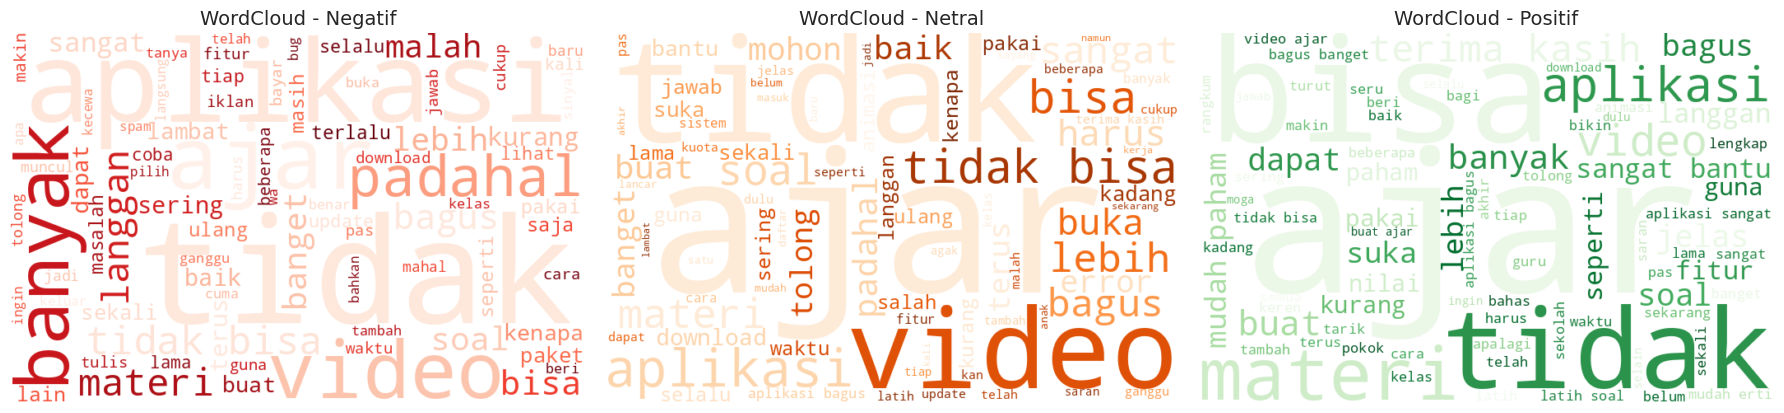

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, ["Negatif", "Netral", "Positif"]):
    teks = " ".join(df.loc[df["label"] == lab, "clean_content"])
    wc = WordCloud(width=700, height=450, background_color="white", colormap="Reds" if lab == "Negatif" else "Oranges" if lab == "Netral" else "Greens", max_words=80, random_state=SEED).generate(teks)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"WordCloud - {lab}", fontsize=14)
plt.tight_layout(); plt.show()

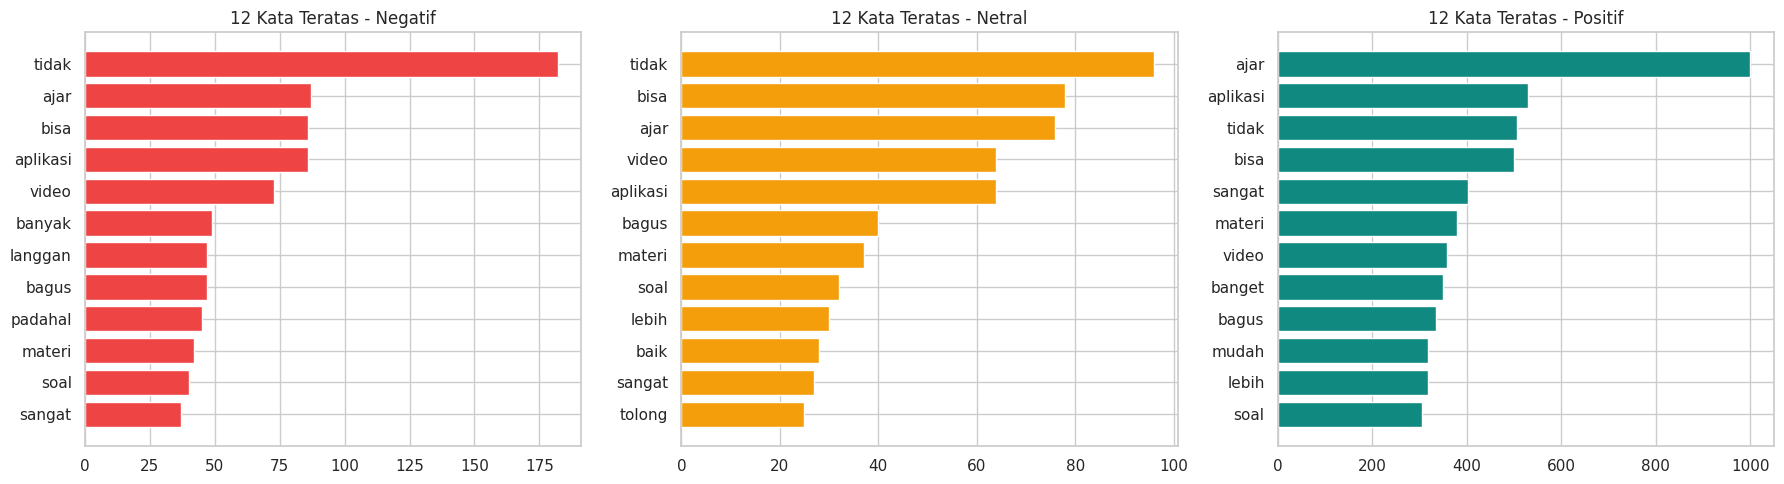

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, ["Negatif", "Netral", "Positif"]):
    top = pd.Series(" ".join(df.loc[df["label"] == lab, "clean_content"]).split()).value_counts().head(12)[::-1]
    ax.barh(top.index, top.values, color=PALETTE[lab]); ax.set_title(f"12 Kata Teratas - {lab}")
plt.tight_layout(); plt.show()

In [15]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean_content"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)

print(f"Data latih: {len(X_train_txt)} | Data uji: {len(X_test_txt)}")
pd.DataFrame({"Latih": y_train.value_counts(), "Uji": y_test.value_counts()})

Data latih: 799 | Data uji: 200


,Latih,Uji
label,,
Positif,625,156
Negatif,105,27
Netral,69,17


In [16]:
def buat_sampler(y, faktor=1.0):
    k_min = int(pd.Series(y).value_counts().min() * faktor)
    return SMOTE(k_neighbors=min(5, k_min-1), random_state=SEED) if k_min > 1 else RandomOverSampler(random_state=SEED)

N_FOLD = 5
pipe = ImbPipeline([
    ("tfidf", TfidfVectorizer(sublinear_tf=True)),
    ("smote", buat_sampler(y_train, faktor=(N_FOLD-1)/N_FOLD)),
    ("nb", MultinomialNB())
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [2000, 5000],
    "tfidf__min_df": [1, 2, 3],
    "nb__alpha": [0.05, 0.1, 0.3, 0.5, 1.0]
}

gs = GridSearchCV(pipe, param_grid, scoring="f1_macro", cv=StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED), n_jobs=-1)
gs.fit(X_train_txt, y_train)

print("Parameter terbaik:", gs.best_params_)
print(f"F1-macro CV terbaik: {gs.best_score_:.4f}")

hasil_grid = pd.DataFrame(gs.cv_results_)[["param_tfidf__ngram_range", "param_tfidf__max_features", "param_tfidf__min_df", "param_nb__alpha", "mean_test_score"]]\
    .rename(columns=lambda c: c.replace("param_", "")).sort_values("mean_test_score", ascending=False)
hasil_grid.head(10)

Parameter terbaik: {'nb__alpha': 1.0, 'tfidf__max_features': 2000, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 1)}
F1-macro CV terbaik: 0.5642


,tfidf__ngram_range,tfidf__max_features,tfidf__min_df,nb__alpha,mean_test_score
58,"(1, 1)",5000,3,1.0,0.564168
52,"(1, 1)",2000,3,1.0,0.564168
25,"(1, 2)",2000,1,0.3,0.561766
48,"(1, 1)",2000,1,1.0,0.561498
49,"(1, 2)",2000,1,1.0,0.561434
51,"(1, 2)",2000,2,1.0,0.560820
54,"(1, 1)",5000,1,1.0,0.560446
59,"(1, 2)",5000,3,1.0,0.559488
53,"(1, 2)",2000,3,1.0,0.559488
40,"(1, 1)",2000,3,0.5,0.558522


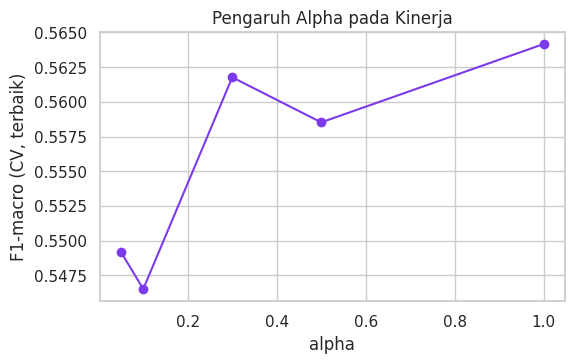

In [19]:
# Pengaruh alpha (Laplace smoothing) terhadap F1-macro
g = hasil_grid.groupby("nb__alpha")["mean_test_score"].max()
plt.figure(figsize=(6, 3.5)); plt.plot(g.index, g.values, marker="o", color="#7C3AED")
plt.xlabel("alpha"); plt.ylabel("F1-macro (CV, terbaik)"); plt.title("Pengaruh Alpha pada Kinerja"); plt.show()

In [20]:
bp = gs.best_params_
vectorizer = TfidfVectorizer(ngram_range=bp["tfidf__ngram_range"], max_features=bp["tfidf__max_features"],
                             min_df=bp["tfidf__min_df"], sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_txt)
X_test = vectorizer.transform(X_test_txt)
print("Bentuk matriks TF-IDF latih:", X_train.shape)

sampler = buat_sampler(y_train) # fit hanya di data latih
X_train_bal, y_train_bal = sampler.fit_resample(X_train, y_train) # SMOTE hanya pada data latih
print(type(sampler).__name__)
pd.DataFrame({"Sebelum": y_train.value_counts(), "Sesudah": pd.Series(y_train_bal).value_counts()})

Bentuk matriks TF-IDF latih: (799, 969)
SMOTE


,Sebelum,Sesudah
label,,
Positif,625,625
Negatif,105,625
Netral,69,625


In [21]:
model = MultinomialNB(alpha=bp["nb__alpha"])
model.fit(X_train_bal, y_train_bal)
classes = list(model.classes_)
print(f"Model Multinomial Naive Bayes dilatih (alpha={bp['nb__alpha']}), kelas: {classes}")

Model Multinomial Naive Bayes dilatih (alpha=1.0), kelas: [np.str_('Negatif'), np.str_('Netral'), np.str_('Positif')]


In [22]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

metrik = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
}
tabel_metrik = pd.DataFrame(metrik, index=["Nilai"]).T
display(tabel_metrik.style.format("{:.4f}").background_gradient(cmap="Purples"))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

,Nilai
Accuracy,0.7300
Precision (macro),0.4688
Recall (macro),0.5103
F1-Score (macro),0.4797
F1-Score (weighted),0.7524



Classification Report:

              precision    recall  f1-score   support

     Negatif       0.37      0.59      0.46        27
      Netral       0.10      0.12      0.11        17
     Positif       0.93      0.82      0.87       156

    accuracy                           0.73       200
   macro avg       0.47      0.51      0.48       200
weighted avg       0.79      0.73      0.75       200



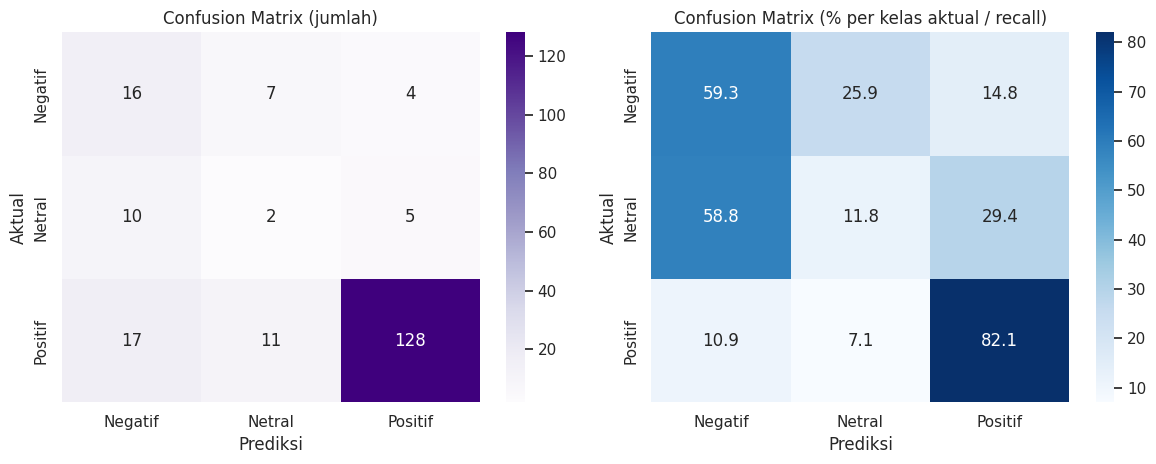

In [23]:
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=classes, yticklabels=classes, ax=ax[0])
ax[0].set(title="Confusion Matrix (jumlah)", xlabel="Prediksi", ylabel="Aktual")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[1])
ax[1].set(title="Confusion Matrix (% per kelas aktual / recall)", xlabel="Prediksi", ylabel="Aktual")
plt.tight_layout(); plt.show()

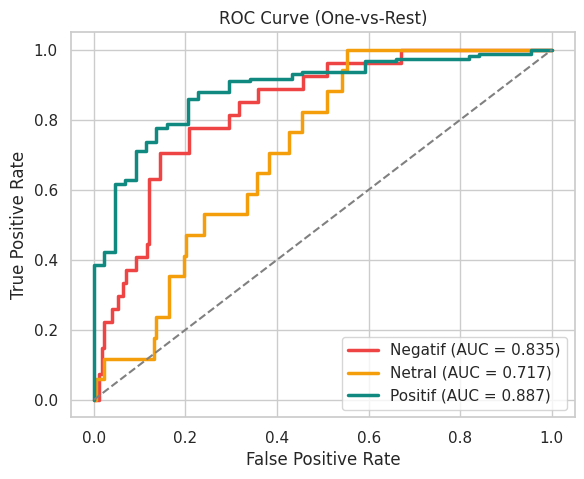

ROC-AUC macro: 0.8129


In [24]:
# ROC Curve One-vs-Rest
Y = label_binarize(y_test, classes=classes)
plt.figure(figsize=(6.5, 5))
aucs = {}
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y[:, i], y_prob[:, i])
    aucs[c] = roc_auc_score(Y[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, lw=2.5, color=PALETTE[c], label=f"{c} (AUC = {aucs[c]:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve (One-vs-Rest)")
plt.legend(loc="lower right"); plt.show()
print(f"ROC-AUC macro: {np.mean(list(aucs.values())):.4f}")

,Fold,Accuracy,F1-macro
0,Fold 1,0.7750,0.5750
1,Fold 2,0.7562,0.5872
2,Fold 3,0.8000,0.6473
3,Fold 4,0.7562,0.5258
4,Fold 5,0.6918,0.4855


Accuracy : 0.7559 ± 0.0358
F1-macro : 0.5642 ± 0.0552


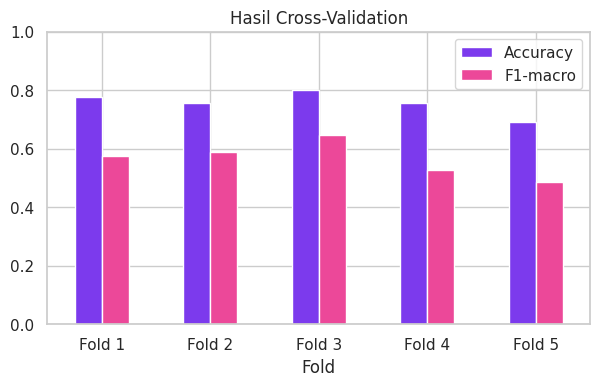

In [25]:
# Cross-Validation pada data latih (TF-IDF + SMOTE dihitung ulang di tiap fold)
best_pipe = ImbPipeline([
    ("tfidf", TfidfVectorizer(ngram_range=bp["tfidf__ngram_range"], max_features=bp["tfidf__max_features"],
                              min_df=bp["tfidf__min_df"], sublinear_tf=True)),
    ("smote", buat_sampler(y_train, faktor=(N_FOLD-1)/N_FOLD)),
    ("nb", MultinomialNB(alpha=bp["nb__alpha"])),
])
skf = StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED)
cv_acc = cross_val_score(best_pipe, X_train_txt, y_train, cv=skf, scoring="accuracy")
cv_f1 = cross_val_score(best_pipe, X_train_txt, y_train, cv=skf, scoring="f1_macro")

cv_df = pd.DataFrame({"Fold": [f"Fold {i+1}" for i in range(N_FOLD)], "Accuracy": cv_acc, "F1-macro": cv_f1})
display(cv_df.style.format({"Accuracy": "{:.4f}", "F1-macro": "{:.4f}"}))
print(f"Accuracy : {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
print(f"F1-macro : {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")

cv_df.set_index("Fold").plot(kind="bar", figsize=(7, 3.8), color=["#7C3AED", "#EC4899"], rot=0)
plt.ylim(0, 1); plt.title("Hasil Cross-Validation"); plt.show()

In [26]:
# Contoh prediksi yang salah (untuk analisis error)
salah = pd.DataFrame({"ulasan": X_test_txt.values, "aktual": y_test.values, "prediksi": y_pred,
                      "keyakinan": y_prob.max(axis=1)})
salah = salah[salah["aktual"] != salah["prediksi"]].sort_values("keyakinan", ascending=False)
print(f"Jumlah salah prediksi: {len(salah)} dari {len(y_test)}")
salah.head(10)

Jumlah salah prediksi: 54 dari 200


,ulasan,aktual,prediksi,keyakinan
143,turut aplikasi bagus yah lebih suka baca buku ...,Negatif,Positif,0.759251
67,kendala akhirakhir tiap pakai aplikasi sering ...,Netral,Negatif,0.729754
121,hai benar benar terima kasih sangat bantu paha...,Negatif,Positif,0.725007
166,seluruh sangat baik sangat bantu ajar utama ba...,Positif,Negatif,0.704965
58,beberapa kali login nomor orang tua namun teta...,Netral,Negatif,0.656496
62,baru coba beberapa hari rasa puas mudah erti b...,Positif,Negatif,0.649143
48,kadang masalah kata server sibuk jaring penuh ...,Positif,Netral,0.644586
25,gasukasinyal jdi buruk lgi muter video langgan...,Negatif,Netral,0.642195
107,cukup baik cuma agak bikin kesel banyak iklan,Positif,Negatif,0.635071
29,seluruh bagus bingung batas jumlah perangkat a...,Positif,Negatif,0.623711


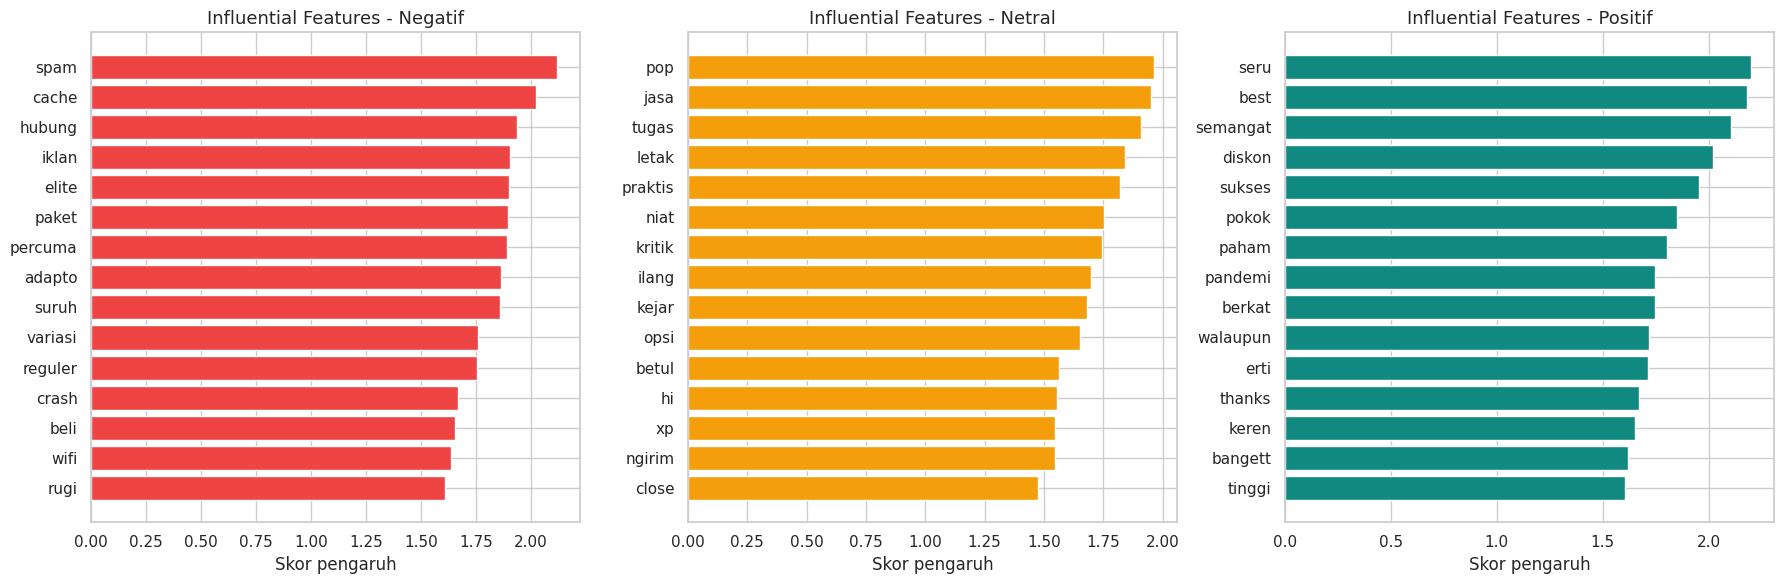

Kelas,Negatif,Netral,Positif
Rank,,,
1,spam,pop,seru
2,cache,jasa,best
3,hubung,tugas,semangat
4,iklan,letak,diskon
5,elite,praktis,sukses
6,paket,niat,pokok
7,percuma,kritik,paham
8,adapto,ilang,pandemi
9,suruh,kejar,berkat


In [27]:
fitur = np.array(vectorizer.get_feature_names_out())
flp = model.feature_log_prob_

def fitur_berpengaruh(top_n=15):
    rows = []
    for i, c in enumerate(classes):
        selisih = flp[i] - np.delete(flp, i, axis=0).mean(axis=0)
        for rank, j in enumerate(np.argsort(selisih)[::-1][:top_n], 1):
            rows.append({"Kelas": c, "Rank": rank, "Fitur": fitur[j], "Skor Pengaruh": selisih[j],
                         "Rasio Odds": np.exp(selisih[j]), "log P(kata|kelas)": flp[i, j]})
    return pd.DataFrame(rows)

inf = fitur_berpengaruh(15)
fig, axes = plt.subplots(1, 3, figsize=(18,6))
for ax, c in zip(axes, classes):
    d = inf[inf["Kelas"] == c].sort_values("Skor Pengaruh")
    ax.barh(d["Fitur"], d["Skor Pengaruh"], color=PALETTE[c]); ax.set_title(f"Influential Features - {c}", fontsize=13)
    ax.set_xlabel("Skor pengaruh")
plt.tight_layout(); plt.show()

display(inf.pivot(index="Rank", columns="Kelas", values="Fitur")[classes])

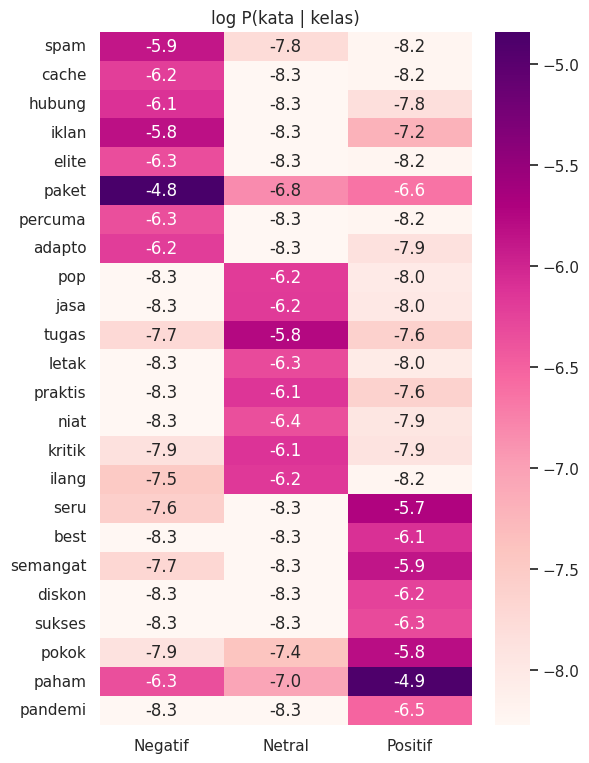

In [28]:
# Heatmap log-probabilitas kata teratas tiap kelas
pilih = []
for i in range(len(classes)):
    selisih = flp[i] - np.delete(flp, i, axis=0).mean(axis=0)
    pilih += list(np.argsort(selisih)[::-1][:8])
pilih = list(dict.fromkeys(pilih))

hm = pd.DataFrame(flp[:, pilih].T, index=fitur[pilih], columns=classes)
plt.figure(figsize=(6, 9)); sns.heatmap(hm, annot=True, fmt=".1f", cmap="RdPu"); plt.title("log P(kata | kelas)"); plt.show()

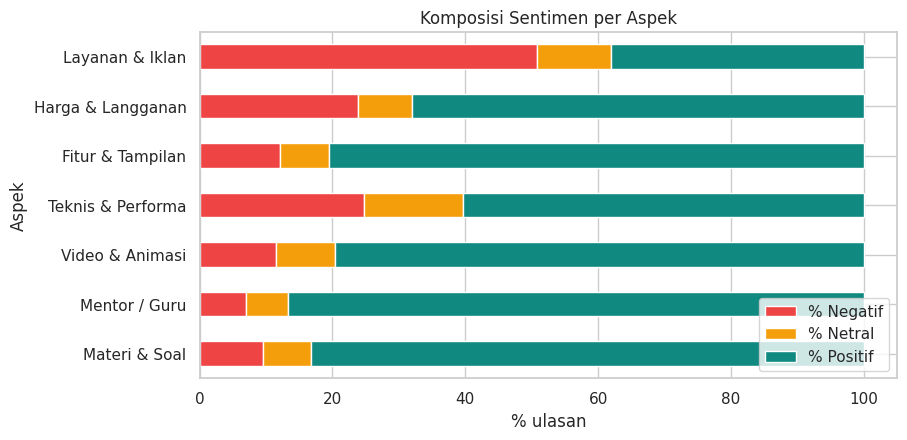

,Aspek,Jumlah Ulasan,Rata-rata Rating,% Negatif,% Netral,% Positif
0,Materi & Soal,638,4.35,9.6,7.2,83.2
1,Mentor / Guru,629,4.48,7.0,6.4,86.6
2,Video & Animasi,402,4.25,11.4,9.0,79.6
3,Teknis & Performa,315,3.63,24.8,14.9,60.3
4,Fitur & Tampilan,266,4.23,12.0,7.5,80.5
5,Harga & Langganan,260,3.83,23.8,8.1,68.1
6,Layanan & Iklan,63,2.78,50.8,11.1,38.1


In [29]:
ASPEK = {
    "Mentor / Guru": r"guru|mentor|pengajar|tutor|kakak|penjelasan|menjelaskan",
    "Materi & Soal": r"materi|soal|latihan|rangkuman|pembahasan|kuis|pelajaran|kurikulum|bab",
    "Video & Animasi": r"video|animasi|tayang|nonton|subtitle|suara",
    "Harga & Langganan": r"harga|mahal|langganan|berlangganan|paket|bayar|biaya|promo|diskon|gratis|saldo|refund",
    "Teknis & Performa": r"error|bug|crash|lemot|lambat|loading|download|kuota|login|update|hang|ngelag|tidak bisa|gak bisa|susah",
    "Fitur & Tampilan": r"fitur|tampilan|menu|interface|desain|navigasi|opsi",
    "Layanan & Iklan": r"spam|iklan|telepon|sales|cs|customer|layanan|notifikasi|tawar",
}

low = df["content"].astype(str).str.lower()
rows = []
for nama, pola in ASPEK.items():
    m = low.str.contains(pola, regex=True); sub = df[m]
    rows.append({"Aspek": nama, "Jumlah Ulasan": int(m.sum()), "Rata-rata Rating": sub["score"].mean(),
                 "% Negatif": (sub["label"] == "Negatif").mean() * 100, "% Netral": (sub["label"] == "Netral").mean() * 100,
                 "% Positif": (sub["label"] == "Positif").mean() * 100})

asp = pd.DataFrame(rows).sort_values("Jumlah Ulasan", ascending=False).reset_index(drop=True)
asp.set_index("Aspek")[["% Negatif", "% Netral", "% Positif"]].plot(
    kind="barh", stacked=True, figsize=(9, 4.5), color=[PALETTE["Negatif"], PALETTE["Netral"], PALETTE["Positif"]])
plt.title("Komposisi Sentimen per Aspek"); plt.legend(loc="lower right"); plt.xlabel("% ulasan"); plt.show()

display(asp.style.format({"Rata-rata Rating": "{:.2f}", "% Negatif": "{:.1f}", "% Netral": "{:.1f}", "% Positif": "{:.1f}"})\
        .background_gradient(cmap="Reds", subset=["% Negatif"]))

In [30]:
def prediksi(teks, top_k=6):
    bersih = bersihkan_teks(teks)
    X = vectorizer.transform([bersih])
    p = model.predict_proba(X)[0]
    pred = classes[p.argmax()]

    kontrib = []
    ref = classes[np.argsort(p)[::-1][1]]
    for j in X.nonzero()[1]:
        kontrib.append((fitur[j], (flp[classes.index(pred), j] - flp[classes.index(ref), j]) * X[0, j]))
    kontrib = sorted(kontrib, key=lambda x: x[1])[::-1][:top_k]

    return pred, dict(zip(classes, p.round(3))), kontrib

for t in ["Aplikasinya bagus banget, materi lengkap dan gurunya jelas!",
          "Sering error, tidak bisa login, kecewa sekali",
          "Lumayan lah tapi masih banyak yang perlu diperbaiki"]:
    pred, prob, kontrib = prediksi(t)
    print(f"\n{t}\n-> {pred} {prob}\n   kata pendorong: {[k for k, v in kontrib]}")


Aplikasinya bagus banget, materi lengkap dan gurunya jelas!
-> Positif {np.str_('Negatif'): np.float64(0.07), np.str_('Netral'): np.float64(0.215), np.str_('Positif'): np.float64(0.715)}
   kata pendorong: ['jelas', 'guru', 'banget', 'lengkap', 'materi', 'aplikasi']

Sering error, tidak bisa login, kecewa sekali
-> Netral {np.str_('Negatif'): np.float64(0.401), np.str_('Netral'): np.float64(0.552), np.str_('Positif'): np.float64(0.047)}
   kata pendorong: ['login', 'error', 'bisa', 'tidak', 'sekali', 'sering']

Lumayan lah tapi masih banyak yang perlu diperbaiki
-> Netral {np.str_('Negatif'): np.float64(0.238), np.str_('Netral'): np.float64(0.404), np.str_('Positif'): np.float64(0.359)}
   kata pendorong: ['masih', 'baik', 'perlu', 'banyak', 'lumayan']


In [31]:
import joblib
joblib.dump({"vectorizer": vectorizer, "model": model, "classes": classes, "best_params": bp,
             "metrics": metrik, "cm": cm}, "model_nb_sentimen.joblib")
df.to_csv("data_bersih_berlabel.csv", index=False)
print("Tersimpan: model_nb_sentimen.joblib, data_bersih_berlabel.csv, stem_cache.json")

Tersimpan: model_nb_sentimen.joblib, data_bersih_berlabel.csv, stem_cache.json
